In [1]:
# importing nec libs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

In [2]:
# load the model
wdf = pd.read_csv('/Users/raghunandanms/Desktop/AICW_2.0/Spoke Engg/Unit 3-Understanding Machine Learning/Lab/Lab 22 winequality-red.csv')
wdf.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
def log_transform(col):
    return np.log(col[0])
wdf['residual sugar'] = wdf[['residual sugar']].apply(log_transform, axis=1)
wdf['chlorides'] = wdf[['chlorides']].apply(log_transform, axis=1)
wdf['free sulfur dioxide'] = wdf[['free sulfur dioxide']].apply(log_transform, axis=1)
wdf['total sulfur dioxide'] = wdf[['total sulfur dioxide']].apply(log_transform, axis=1)
wdf['sulphates'] = wdf[['sulphates']].apply(log_transform, axis=1)

/var/folders/zq/dgfk_fp94xx1cgj558mgrdlm0000gn/T/ipykernel_54103/706812816.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return np.log(col[0])
/var/folders/zq/dgfk_fp94xx1cgj558mgrdlm0000gn/T/ipykernel_54103/706812816.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return np.log(col[0])
/var/folders/zq/dgfk_fp94xx1cgj558mgrdlm0000gn/T/ipykernel_54103/706812816.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return np.l

In [4]:
# split the dataset - dv y - idv x
x = wdf.drop(columns=['quality'])
y = wdf['quality']

In [6]:
from imblearn.over_sampling import SMOTE
oversample = SMOTE(k_neighbors=4)
x, y = oversample.fit_resample(x.fillna(0), y)

In [7]:
y.value_counts()

quality
5    681
6    681
7    681
4    681
8    681
3    681
Name: count, dtype: int64

In [8]:
x_train, x_test, y_train, y_test = train_test_split(x, y, 
                                                   test_size=0.2,
                                                   random_state=42)

In [9]:
x_train.shape, x_test.shape

((3268, 11), (818, 11))

In [11]:
# 1. logistic regression - sigmoid function
lr_model = LogisticRegression()
lr_model.fit(x_train, y_train)
lr_pred = lr_model.predict(x_test)
lr_pred

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


array([3, 5, 3, 7, 3, 5, 5, 5, 5, 4, 8, 7, 5, 3, 8, 5, 6, 5, 8, 5, 7, 3,
       5, 5, 4, 3, 7, 3, 4, 7, 7, 3, 8, 8, 3, 6, 5, 8, 3, 4, 7, 8, 5, 7,
       7, 4, 7, 4, 3, 7, 7, 7, 6, 6, 6, 5, 5, 8, 5, 4, 6, 3, 3, 3, 8, 5,
       6, 8, 8, 6, 4, 3, 5, 5, 5, 5, 4, 4, 7, 3, 8, 7, 6, 5, 5, 8, 7, 4,
       8, 4, 3, 6, 6, 3, 4, 7, 4, 4, 7, 8, 3, 8, 3, 5, 5, 5, 7, 6, 8, 7,
       4, 3, 7, 5, 5, 4, 3, 8, 3, 5, 5, 5, 8, 5, 6, 7, 7, 4, 4, 3, 6, 8,
       4, 3, 3, 3, 8, 5, 5, 3, 7, 4, 4, 6, 7, 7, 6, 4, 8, 4, 4, 5, 4, 5,
       3, 4, 4, 8, 6, 8, 4, 3, 8, 6, 8, 3, 7, 6, 3, 4, 4, 8, 4, 4, 7, 7,
       4, 3, 7, 3, 3, 6, 8, 7, 7, 6, 4, 6, 7, 7, 7, 5, 6, 7, 6, 4, 3, 3,
       3, 7, 6, 7, 3, 4, 3, 7, 3, 5, 4, 6, 8, 8, 7, 5, 7, 7, 5, 5, 7, 4,
       5, 3, 7, 8, 8, 3, 5, 3, 6, 7, 7, 3, 7, 4, 5, 5, 8, 7, 5, 4, 4, 8,
       3, 5, 6, 4, 6, 7, 7, 8, 6, 7, 7, 8, 4, 8, 5, 3, 5, 5, 3, 8, 3, 7,
       6, 3, 7, 7, 7, 3, 6, 3, 4, 7, 4, 4, 5, 8, 3, 8, 6, 8, 3, 7, 5, 5,
       4, 4, 4, 8, 8, 3, 4, 5, 8, 3, 3, 5, 7, 4, 4,

In [12]:
# accuracy
acc = accuracy_score(y_test, lr_pred)
acc * 100

53.0562347188264

In [14]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, lr_pred)
cm

array([[113,   7,   8,   4,   0,   0],
       [ 36,  53,  29,  12,   1,   0],
       [ 13,  28,  82,  17,  10,   0],
       [  7,  27,  42,  36,  29,  14],
       [  1,   6,   1,  15,  62,  31],
       [  0,   0,   0,   0,  46,  88]])

In [15]:
rfc_model = RandomForestClassifier()
rfc_model.fit(x_train, y_train)
rfc_pred = rfc_model.predict(x_test)
acc_rfc = accuracy_score(y_test, rfc_pred)
acc_rfc * 100

87.04156479217605

# Unsupervised ML - K Means Clustering

In [16]:
from sklearn.cluster import KMeans

In [17]:
# load dataset - lab23 Wholesale customers data.csv
df = pd.read_csv('/Users/raghunandanms/Desktop/AICW_2.0/Spoke Engg/Unit 3-Understanding Machine Learning/Lab/Lab 23 Wholesale customers data.csv')
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [18]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [20]:
# standardization 
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)
pd.DataFrame(df_scaled)

,0,1,2,3,4,5,6,7
0,1.448652,0.590668,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,1.448652,0.590668,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,1.448652,0.590668,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,-0.690297,0.590668,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,1.448652,0.590668,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347
...,...,...,...,...,...,...,...,...
435,-0.690297,0.590668,1.401312,0.848446,0.850760,2.075222,-0.566831,0.241091
436,-0.690297,0.590668,2.155293,-0.592142,-0.757165,0.296561,-0.585519,0.291501
437,1.448652,0.590668,0.200326,1.314671,2.348386,-0.543380,2.511218,0.121456
438,-0.690297,0.590668,-0.135384,-0.517536,-0.602514,-0.419441,-0.569770,0.213046


In [22]:
# define kmeans and train it
kmeans = KMeans(n_clusters=2, init='k-means++')
# training
kmeans.fit(df_scaled)

,n_clusters,2
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


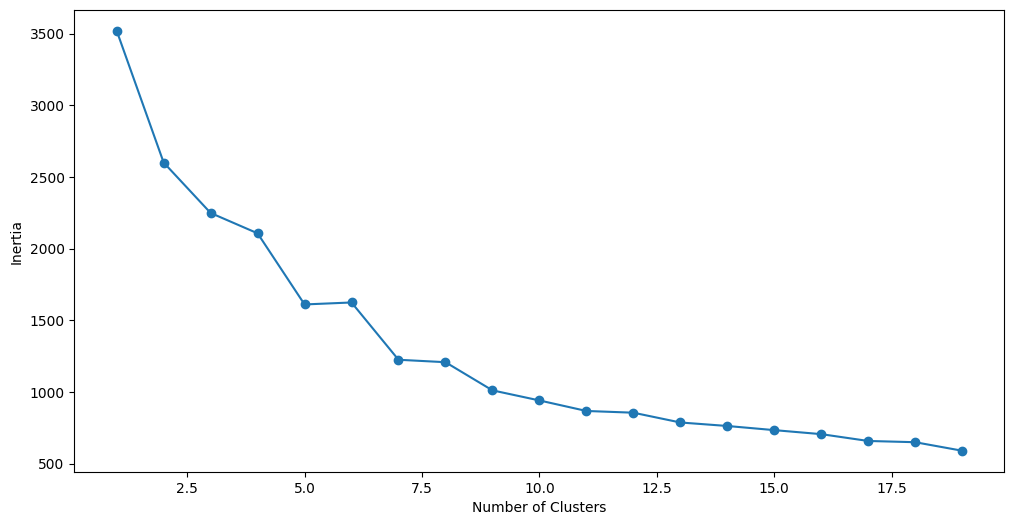

In [23]:
SSE = []
for cluster in range(1, 20):
    kmeans = KMeans(n_clusters=cluster, init='k-means++')
    kmeans.fit(df_scaled)
    SSE.append(kmeans.inertia_)

frame = pd.DataFrame({'Cluster':range(1, 20), 'SSE':SSE})
plt.figure(figsize=(12, 6))
plt.plot(frame['Cluster'], frame['SSE'], marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.show()

In [24]:
# for k = 5
kmeans = KMeans(n_clusters=5, init='k-means++')
kmeans.fit(df_scaled)
pred = kmeans.predict(df_scaled)

In [25]:
frame = pd.DataFrame(df_scaled)
frame['cluster']= pred
frame['cluster'].value_counts()

cluster
3    200
1    126
4     90
2     14
0     10
Name: count, dtype: int64

In [26]:
kmeans = KMeans(n_clusters=7, init='k-means++')
kmeans.fit(df_scaled)
pred = kmeans.predict(df_scaled)
frame = pd.DataFrame(df_scaled)
frame['cluster']= pred
frame['cluster'].value_counts()

cluster
2    156
0    125
1     84
6     59
4     10
5      5
3      1
Name: count, dtype: int64

## Simple ANN

In [27]:
# Importing nec libs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
# load the dataset
cdf = pd.read_csv('/Users/raghunandanms/Desktop/AICW_2.0/Spoke Engg/Unit 4-Advanced Machine Learning & Deep Learning (For Data Scientists)/Lab/Lab 24 breast-cancer-wisconsin.csv')
cdf.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [29]:
cdf.shape

(569, 33)

In [30]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [31]:
cdf.isnull().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [32]:
cdf.loc[cdf['diagnosis']=='M', 'benign_0_mal_1'] = 1
cdf.loc[cdf['diagnosis']=='B', 'benign_0_mal_1'] = 0

In [33]:
cdf.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32,benign_0_mal_1
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN,1.0
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN,1.0
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN,1.0
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN,1.0
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN,1.0


In [38]:
# removing the cols - id, unamed:32 and diagnosis
# cdf = cdf.drop(columns=['id', 'Unnamed: 32', 'diagnosis'], axis=1)
cdf.columns

Index(['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'benign_0_mal_1'],
      dtype='object')

<Axes: xlabel='benign_0_mal_1', ylabel='count'>

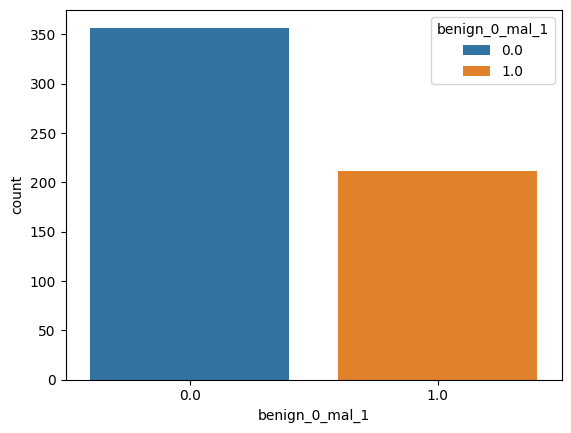

In [39]:
sns.countplot(x='benign_0_mal_1', data=cdf, hue='benign_0_mal_1')

In [40]:
cdf['benign_0_mal_1'].value_counts()

benign_0_mal_1
0.0    357
1.0    212
Name: count, dtype: int64

<Axes: >

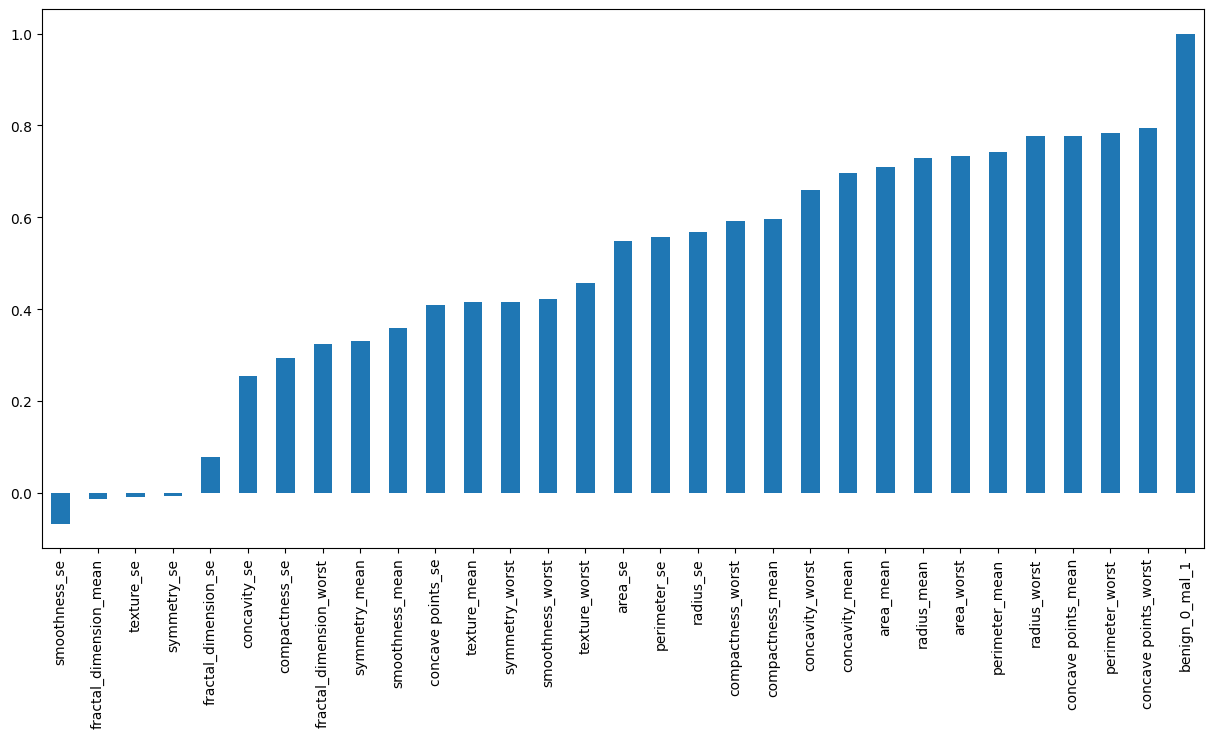

In [42]:
plt.figure(figsize=(15, 7))
cdf.corr()['benign_0_mal_1'].sort_values().plot(kind='bar')

In [43]:
# independent var and dependent var
x = cdf.drop(['benign_0_mal_1'], axis=1).values
y = cdf['benign_0_mal_1'].values

In [44]:
# train test split
xtr, xte, ytr, yte = train_test_split(x, y, train_size=0.8, random_state=50)

In [45]:
xtr.shape, xte.shape

((455, 30), (114, 30))

In [46]:
# scaling 1. StandardScaler 2. MinMaxScaler 3. RobustScaler
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
xtr = scaler.fit_transform(xtr)
xte = scaler.transform(xte) # to prevent data leakages

In [47]:
!pip install tensorflow


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [48]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, InputLayer, Dropout

In [51]:
# create the model
model1 = Sequential()
model1.add(InputLayer(input_shape=(30,))) # input layer with 26 input features
model1.add(Dense(26, activation='relu')) # First hidden layer
model1.add(Dense(15, activation='relu')) # Second hidden layer
model1.add(Dense(1, activation='sigmoid'))
model1.summary()

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 26)             │           806 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           405 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,227 (4.79 KB)

 Trainable params: 1,227 (4.79 KB)

 Non-trainable params: 0 (0.00 B)

In [52]:
model1.compile(loss='binary_crossentropy', 
              optimizer='adam',
              metrics=['accuracy'])

In [54]:
model1.fit(x=xtr, y=ytr, epochs=100, validation_data=(xte, yte))

Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5604 - loss: 0.6746 - val_accuracy: 0.6842 - val_loss: 0.6592
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8220 - loss: 0.6378 - val_accuracy: 0.8596 - val_loss: 0.6080
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8791 - loss: 0.5898 - val_accuracy: 0.9035 - val_loss: 0.5471
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8615 - loss: 0.5375 - val_accuracy: 0.9211 - val_loss: 0.4932
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8967 - loss: 0.4845 - val_accuracy: 0.9649 - val_loss: 0.4422
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9121 - loss: 0.4325 - val_accuracy: 0.9649 - val_loss: 0.3874
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9253 - loss: 0.3799 - val_accuracy: 0.9649 - val_loss: 0.3347
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9363 - loss: 0.3333 - val_accuracy: 0.9737 - v

<Axes: >

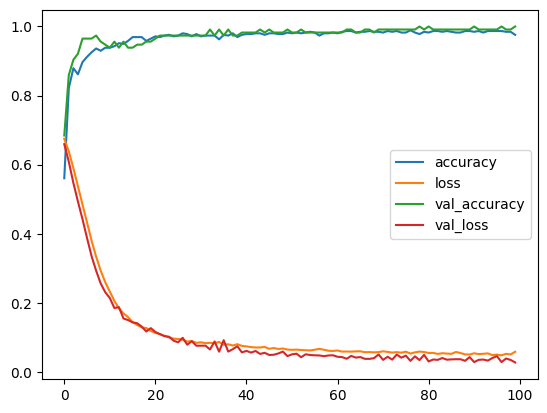

In [55]:
model_loss = pd.DataFrame(model1.history.history)
model_loss.plot()